In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
# Loading the amazon product dataset 
df = pd.read_csv("/Users/jomachase/Documents/Ironhack/Labs/Week5/Day2/lab-eda-bivariate_clone/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


## Part 1: Analyzing Best-Seller Trends Across Product Categories

1. **Crosstab Analysis**:

In [4]:
# showing crosstab for category and isBestSeller
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [5]:
# Calculation of the proportion of best-sellers for each category
crosstab_result['proportion'] = crosstab_result[True] / (crosstab_result[True] + crosstab_result[False])

# Sorting of categories based on the proportion in descending order
sorted_proportions = crosstab_result['proportion'].sort_values(ascending=False)

sorted_proportions

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Name: proportion, Length: 296, dtype: float64

Yes, there are categories where being a best-seller is more prevalent. Based on my analysis, the following categories exhibit the highest proportions of best-sellers:

1. Grocery: 5.81%
2. Smart Home Security & Lighting: 5.77%
3. Health & Personal Care: 5.77%


2. **Statistical Tests**:

In [6]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36684.23786636857), np.float64(0.0))

In [7]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

In [8]:
crosstab_result.iloc[:,:-1]

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [9]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result.iloc[:,:-1], method="cramer")

0.1222829439760564

The Cramér's V value of 0.122 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong between best-seller status and category.

 3. **Visualizations**:

In [10]:
crosstab_result#.sort_values()

isBestSeller,False,True,proportion
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [14]:
# Reset index and check current columns
crosstab_result_new = crosstab_result.reset_index()
print(crosstab_result.columns)  # Check current columns

# Set new column names (ensure this matches the number of columns)
crosstab_result_new.columns = ["category", "False", "True", "total"]

# Continue processing
crosstab_result_new_top5 = crosstab_result_new.sort_values(by="False", ascending=False).head(5)
crosstab_result_new_top5 = crosstab_result_new_top5.set_index("category")

# Normalize values
crosstab_result_new_top5["False"] = crosstab_result_new_top5["False"] / crosstab_result_new_top5["total"]
crosstab_result_new_top5["True"] = crosstab_result_new_top5["True"] / crosstab_result_new_top5["total"]
print(crosstab_result_new_top5["False"])
print(crosstab_result_new_top5["True"])

Index([False, True, 'proportion'], dtype='object', name='isBestSeller')
category
Sports & Outdoors                         2.118373e+09
Handmade Clothing, Shoes & Accessories    2.639180e+07
Bath & Body                               1.102650e+07
Beauty                                    1.215633e+06
Birthday Gifts                            1.027144e+07
Name: False, dtype: float64
category
Sports & Outdoors                         836265.0
Handmade Clothing, Shoes & Accessories     19229.0
Bath & Body                                19092.0
Beauty                                     19312.0
Birthday Gifts                             18978.0
Name: True, dtype: float64


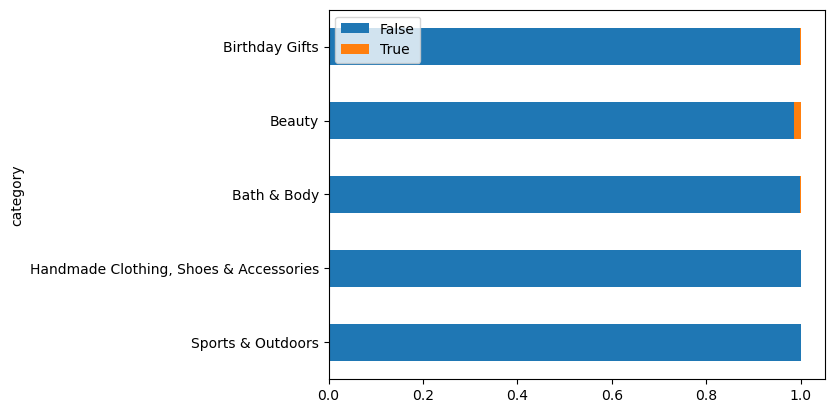

In [59]:
# Plotting a stacked bar chart for the 'crosstab_result' data
#fig, axes = plt.subplots(figsize=(15, 8))
crosstab_result_new_top5.iloc[:,:-1].plot(kind="barh", stacked=True)
plt.show()

#  Part 2: Exploring Product Prices and Ratings Across Categories and Bran

1. **Preliminary Step: Remove outliers in product prices.**

In [12]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


1. **Violin Plots**

/var/folders/2n/vdp8fcl915n4gbp1vcj_4vgw0000gp/T/ipykernel_57659/1651594698.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=outliers[outliers['category'].isin(top20_filter)],


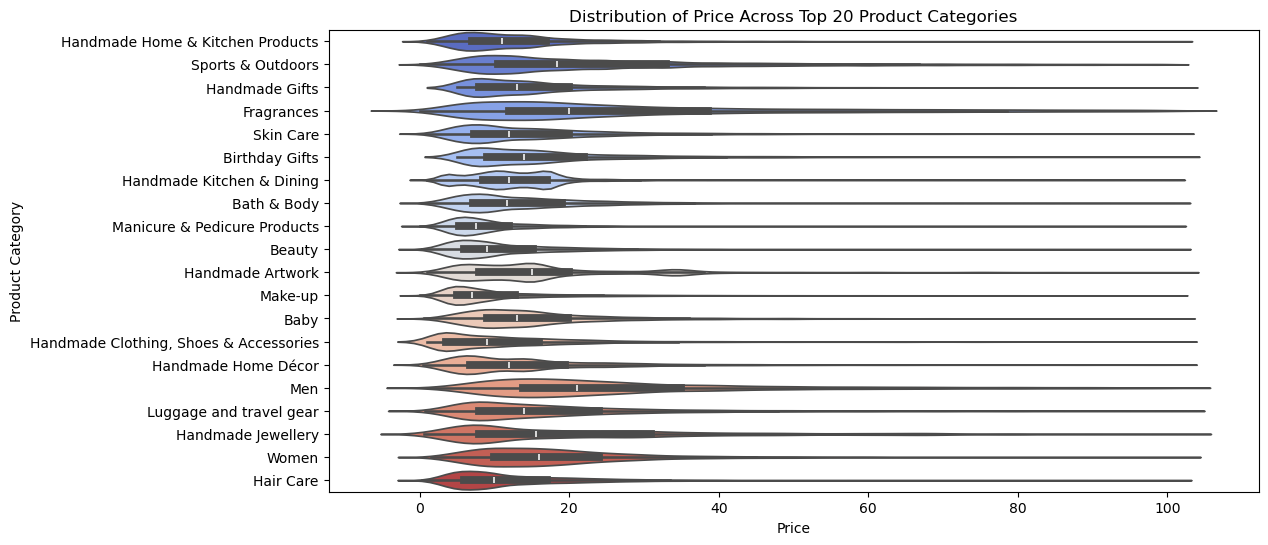

The product category with the highest median price is 'Desktop PCs' with a median price of 74.0.


In [18]:
# Filter out top 20 categories based on count
top20_filter = outliers['category'].value_counts().head(20).index

# Plotting a violin plot to visualize the distribution of 'price' for each 'category'
plt.figure(figsize=(12, 6))
sns.violinplot(data=outliers[outliers['category'].isin(top20_filter)],
                x='price', 
                y='category', 
                palette="coolwarm")
plt.title('Distribution of Price Across Top 20 Product Categories')
plt.xlabel('Price')
plt.ylabel('Product Category')
plt.show()

# Finding the category with the highest median price
median_prices = outliers.groupby('category')['price'].median()
highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()

print(f"The product category with the highest median price is '{highest_median_category}' with a median price of {highest_median_value}.")

2. **Bar Plots**

/var/folders/2n/vdp8fcl915n4gbp1vcj_4vgw0000gp/T/ipykernel_57659/2962892910.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=average_prices[top10_filter].index, y=average_prices[top10_filter].values, palette="viridis")


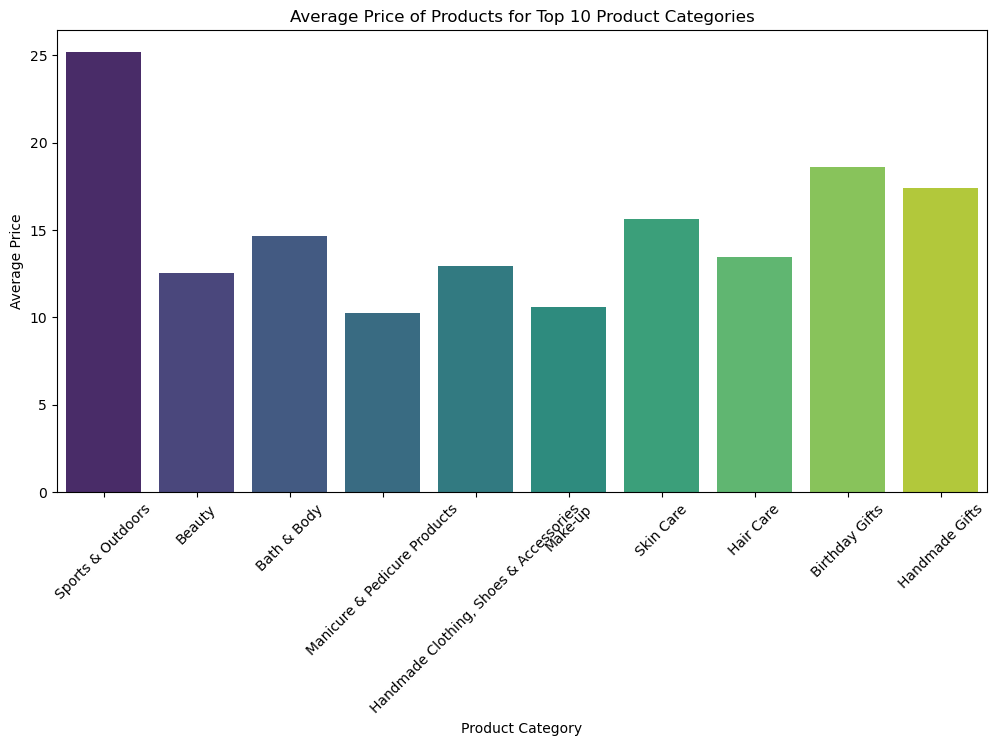

The product category with the highest average price is 'Motherboards' with an average price of 68.77243243243242.


In [19]:
# Calculate average price for each category
average_prices = outliers.groupby('category')['price'].mean()

# Filter out top 10 categories based on count
top10_filter = outliers['category'].value_counts().head(10).index

# Created a bar chart for average prices of top 10 categories
plt.figure(figsize=(12, 6))
sns.barplot(x=average_prices[top10_filter].index, y=average_prices[top10_filter].values, palette="viridis")
plt.title('Average Price of Products for Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

# Finding the category with the highest average price
highest_avg_category = average_prices.idxmax()
highest_avg_value = average_prices.max()

print(f"The product category with the highest average price is '{highest_avg_category}' with an average price of {highest_avg_value}.")

3. **Box Plots**

/var/folders/2n/vdp8fcl915n4gbp1vcj_4vgw0000gp/T/ipykernel_57659/2530422972.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=outliers[outliers['category'].isin(top10_categories)],


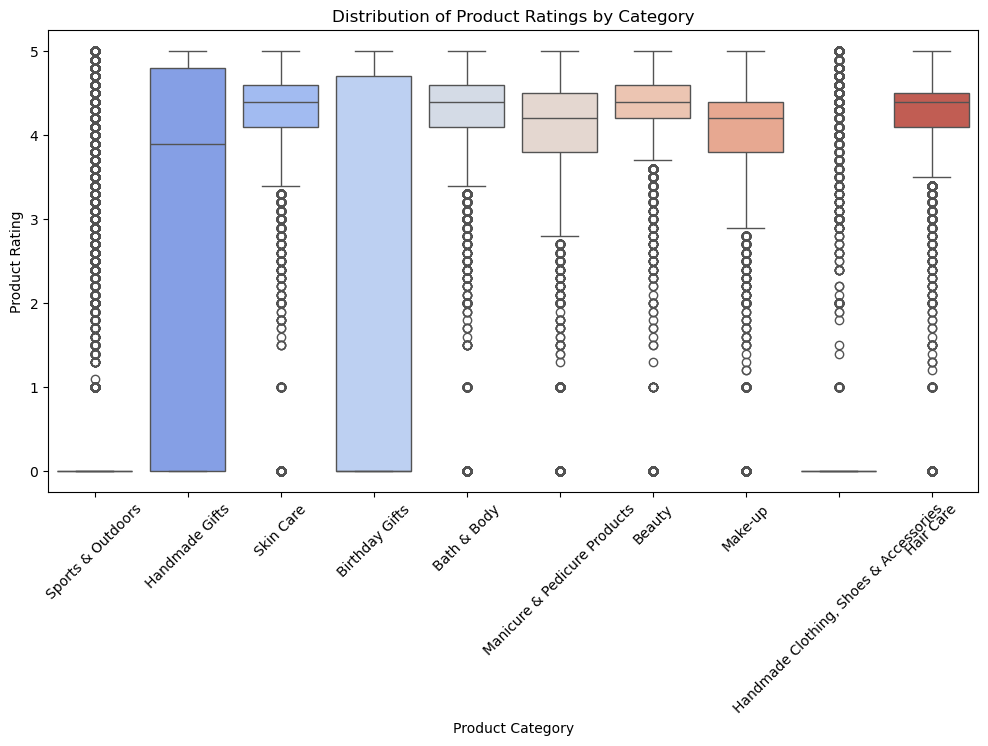

The category that tends to receive the highest median rating is 'Computer Memory' with a median rating of 4.7.


In [22]:
# Filter out top 10 categories based on count for box plots
top10_categories = outliers['category'].value_counts().head(10).index

# Created box plots to visualize the distribution of ratings
plt.figure(figsize=(12, 6))
sns.boxplot(data=outliers[outliers['category'].isin(top10_categories)],
            x='category', 
            y='stars', 
            palette="coolwarm")
plt.title('Distribution of Product Ratings by Category')
plt.xlabel('Product Category')
plt.ylabel('Product Rating')
plt.xticks(rotation=45)
plt.show()

# Finding the category with the highest median rating
median_ratings = outliers.groupby('category')['stars'].median()
highest_median_rating_category = median_ratings.idxmax()
highest_median_rating_value = median_ratings.max()

print(f"The category that tends to receive the highest median rating is '{highest_median_rating_category}' with a median rating of {highest_median_rating_value}.")

# Part 3: Investigating the Interplay Between Product Prices and Ratings

1. **Correlation Coefficients**

In [34]:
# Calculating the Spearman rank correlation between 'stars' and 'price' 
correlation = outliers['price'].corr(outliers['stars'], method='spearman')
print(correlation)


-0.06679697280768324


In [35]:
# Calculating the Pearson rank correlation between 'stars' and 'price' 
correlation = outliers['price'].corr(outliers['stars'], method='pearson')
print(correlation)


-0.0776729987818131


This negative value, in regards to thr spearman correlation, suggests a weak inverse relationship, meaning that higher star ratings may be associated with lower prices (or vice versa), but the relationship is weak.

This negative value, in regards to thr pearson correlation, value indicates a weak inverse linear relationship between price and stars.


2. **Visualizations**

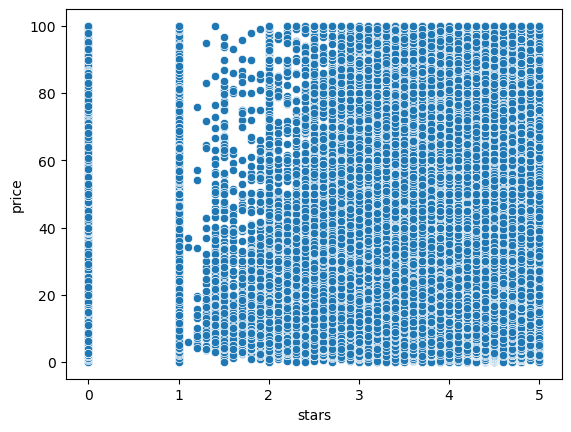

In [36]:
# Plotting a scatter plot to visualize the relationship between 'stars' and 'price'
sns.scatterplot(data=outliers, x='stars', y='price')
plt.show() 

The scatter plot indicates a strong relationship between product ratings and prices, with most products being low-priced regardless of their star ratings.

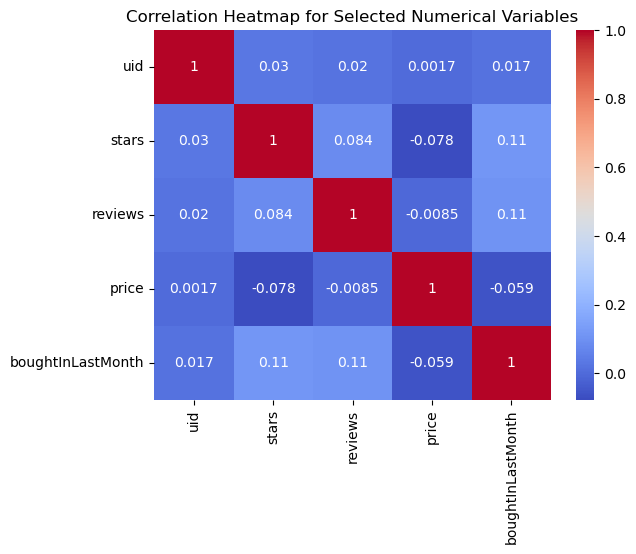

In [37]:
# Drawing the heatmap for the numerical columns

num_heatmap = outliers.select_dtypes(include='number')
sns.heatmap(num_heatmap.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

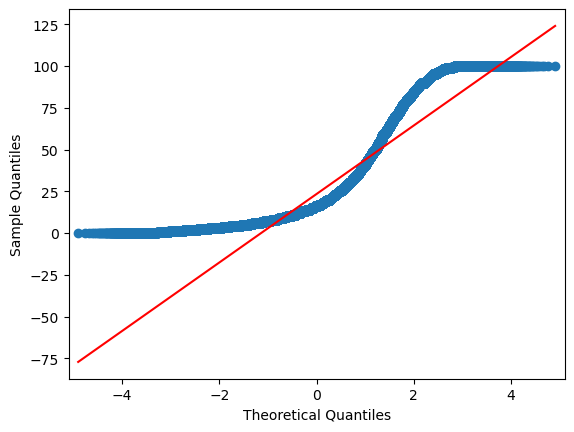

In [38]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(outliers['price'], line='s');
plt.show()

**Heatmap** Overall, the correlations among the variables are relatively weak. There are no strong positive or negative correlations, indicating that the relationships among stars, reviews, price, and boughtInLastMonth are not significant.This weak correlation suggests that other factors might influence these variables more than those shown in the heatmap.

**QQ Plot** the QQ plot shows points that deviate from the reference line, especially at both ends, suggesting that the distribution of product prices does not follow a normal distribution.
